In [1]:
import pandas as pd
import numpy as np
from prophet import Prophet

d:\LATEX\Stage\VSCODE Python\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


In [2]:
"""import sys
!"{sys.executable}" -m pip install prophet """

'import sys\n!"{sys.executable}" -m pip install prophet '

In [3]:
Kandi=pd.read_csv("data\Kandi_final.csv")
Parakou=pd.read_csv("data\Parakou_final.csv")

<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:2: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:2: SyntaxWarning: invalid escape sequence '\P'
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_11700\3890621831.py:1: SyntaxWarning: invalid escape sequence '\K'
  Kandi=pd.read_csv("data\Kandi_final.csv")
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_11700\3890621831.py:2: SyntaxWarning: invalid escape sequence '\P'
  Parakou=pd.read_csv("data\Parakou_final.csv")


In [4]:
Kandi["Pluviometrie"]

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
4012    0.0
4013    0.0
4014    0.0
4015    0.0
4016    0.0
Name: Pluviometrie, Length: 4017, dtype: float64

In [5]:
def changement(x):
    if x<10:
        return f"0{x}"
    else :
        return f"{x}"
Kandi["Date"]=Kandi["annee"].apply(changement)+"-"+Kandi["mois"].apply(changement)+"-"+Kandi["jour"].apply(changement)
Kandi["Date"]=pd.to_datetime(Kandi["Date"])

Parakou["Date"]=Parakou["annee"].apply(changement)+"-"+Parakou["mois"].apply(changement)+"-"+Parakou["jour"].apply(changement)
Parakou["Date"]=pd.to_datetime(Parakou.Date)

In [6]:
Kandi.head()

,Lieu,annee,mois,jour,Pression,Temperature_Max,Temperature_Min,Humidite,Vitesse_Vent,Pluviometrie,Date
0,KANDI_AEROPORT,2015,1,1,979.9,32.0,13.4,32.0,2.4,0.0,2015-01-01
1,KANDI_AEROPORT,2015,1,2,981.4,30.3,17.4,26.0,2.3,0.0,2015-01-02
2,KANDI_AEROPORT,2015,1,3,982.8,29.2,17.7,20.0,3.5,0.0,2015-01-03
3,KANDI_AEROPORT,2015,1,4,983.8,29.0,15.8,20.0,2.8,0.0,2015-01-04
4,KANDI_AEROPORT,2015,1,5,982.7,29.5,13.5,29.0,3.0,0.0,2015-01-05


In [7]:
Kandi["Humidite_lag1"] = Kandi["Humidite"].shift(1)
Kandi["Pression_lag1"] = Kandi["Pression"].shift(1)
Kandi["Vent_lag1"] = Kandi["Vitesse_Vent"].shift(1)
Kandi["Temperature_Max_lag1"] = Kandi["Temperature_Max"].shift(1)
Kandi["Temperature_Min_lag1"] = Kandi["Temperature_Min"].shift(1)
Kandi=Kandi.drop(["Lieu","mois","jour","Temperature_Max","Temperature_Min","Humidite","Vitesse_Vent","Pression"],axis=1)
Kandi=Kandi.dropna(axis=0)

Parakou["Humidite_lag1"] = Parakou["Humidite"].shift(1)
Parakou["Pression_lag1"] = Parakou["Pression"].shift(1)
Parakou["Vent_lag1"] = Parakou["Vitesse_Vent"].shift(1)
Parakou["Temperature_Max_lag1"] = Parakou["Temperature_Max"].shift(1)
Parakou["Temperature_Min_lag1"] = Parakou["Temperature_Min"].shift(1)
Parakou=Parakou.drop(["Lieu","mois","jour","Temperature_Max","Temperature_Min","Humidite","Vitesse_Vent","Pression"],axis=1)
Parakou=Parakou.dropna(axis=0)
Kandi

,annee,Pluviometrie,Date,Humidite_lag1,Pression_lag1,Vent_lag1,Temperature_Max_lag1,Temperature_Min_lag1
1,2015,0.0,2015-01-02,32.0,979.9,2.4,32.0,13.4
2,2015,0.0,2015-01-03,26.0,981.4,2.3,30.3,17.4
3,2015,0.0,2015-01-04,20.0,982.8,3.5,29.2,17.7
4,2015,0.0,2015-01-05,20.0,983.8,2.8,29.0,15.8
5,2015,0.0,2015-01-06,29.0,982.7,3.0,29.5,13.5
...,...,...,...,...,...,...,...,...
4012,2025,0.0,2025-12-27,33.0,977.2,1.5,37.1,20.7
4013,2025,0.0,2025-12-28,28.0,976.9,1.4,37.4,20.4
4014,2025,0.0,2025-12-29,27.0,977.5,2.0,36.9,19.7
4015,2025,0.0,2025-12-30,31.0,978.2,1.5,37.5,19.8


In [8]:
Kandi.rename(columns={"Date":"ds","Pluviometrie":"y"},inplace=True)
Parakou.rename(columns={"Date":"ds","Pluviometrie":"y"},inplace=True)
Kandi_pluie_train=Kandi[Kandi.annee<2024][["ds","y","Humidite_lag1","Pression_lag1","Vent_lag1","Temperature_Max_lag1","Temperature_Min_lag1"]].copy()
Kandi_pluie_test=Kandi[2024<=Kandi.annee][["ds","y","Humidite_lag1","Pression_lag1","Vent_lag1","Temperature_Max_lag1","Temperature_Min_lag1"]].copy()

Parakou_pluie_train=Parakou[Parakou.annee<2024][["ds","y","Humidite_lag1","Pression_lag1","Vent_lag1","Temperature_Max_lag1","Temperature_Min_lag1"]].copy()
Parakou_pluie_test=Parakou[2024<=Parakou.annee][["ds","y","Humidite_lag1","Pression_lag1","Vent_lag1","Temperature_Max_lag1","Temperature_Min_lag1"]].copy()

Kandi_pluie_train

,ds,y,Humidite_lag1,Pression_lag1,Vent_lag1,Temperature_Max_lag1,Temperature_Min_lag1
1,2015-01-02,0.0,32.0,979.9,2.4,32.0,13.4
2,2015-01-03,0.0,26.0,981.4,2.3,30.3,17.4
3,2015-01-04,0.0,20.0,982.8,3.5,29.2,17.7
4,2015-01-05,0.0,20.0,983.8,2.8,29.0,15.8
5,2015-01-06,0.0,29.0,982.7,3.0,29.5,13.5
...,...,...,...,...,...,...,...
3281,2023-12-27,0.0,35.0,979.3,2.1,31.5,13.7
3282,2023-12-28,0.0,26.0,979.4,2.6,32.7,14.1
3283,2023-12-29,0.0,31.0,980.2,2.3,34.0,16.9
3284,2023-12-30,0.0,36.0,979.5,1.9,33.4,15.4


In [9]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
import matplotlib.pyplot as plt
def calcul_erreur_auto(train,test):
    model=Prophet(yearly_seasonality=True,weekly_seasonality=True,daily_seasonality=True)
    model.add_regressor("Humidite_lag1")
    model.add_regressor("Pression_lag1")
    model.add_regressor("Vent_lag1")
    model.add_regressor("Temperature_Max_lag1")
    model.add_regressor("Temperature_Min_lag1")
    model.fit(train)
    forescat=model.predict(test.drop(["y"],axis=1))
    plt.figure(figsize=(10,5))
    plt.plot(test.index,test[["y"]],label="Test")
    plt.plot(test.index,forescat["yhat"],label="Prediction")
    plt.legend()
    return {"Resultats":model,"Forecast":forescat,"MAE":mean_absolute_error(test[["y"]],forescat["yhat"]),"RMSE":np.sqrt(mean_squared_error(test[["y"]],forescat["yhat"]))}

10:11:41 - cmdstanpy - INFO - Chain [1] start processing
10:11:43 - cmdstanpy - INFO - Chain [1] done processing


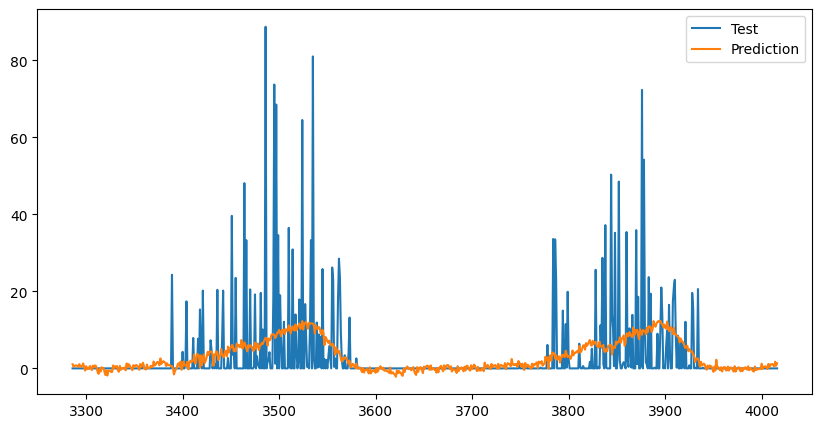

In [10]:
Calcul_Kandi=calcul_erreur_auto(Kandi_pluie_train,Kandi_pluie_test)

10:11:45 - cmdstanpy - INFO - Chain [1] start processing
10:11:45 - cmdstanpy - INFO - Chain [1] done processing


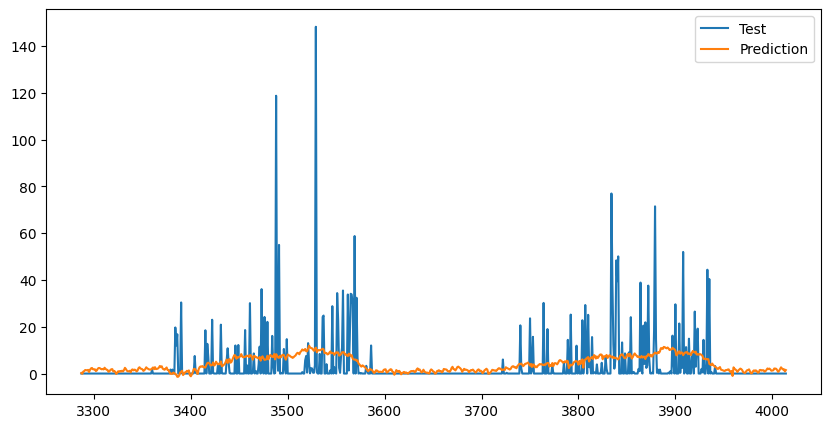

In [11]:
Calcul_Parakou=calcul_erreur_auto(Parakou_pluie_train,Parakou_pluie_test)

In [12]:
Calcul_Kandi

{'Resultats': <prophet.forecaster.Prophet at 0x1fd8eb6e420>,
 'Forecast':             ds     trend  yhat_lower  yhat_upper  trend_lower  trend_upper  \
 0   2024-01-01  0.446663   -9.506069   11.882556     0.446663     0.446663   
 1   2024-01-02  0.446472  -10.863191   11.599827     0.446472     0.446472   
 2   2024-01-03  0.446282  -10.071647   12.008533     0.446282     0.446282   
 3   2024-01-04  0.446091  -10.571151   11.337100     0.446091     0.446091   
 4   2024-01-05  0.445900  -10.746247   12.227447     0.445900     0.445900   
 ..         ...       ...         ...         ...          ...          ...   
 726 2025-12-27  0.308169  -10.145149   12.512609     0.285263     0.330815   
 727 2025-12-28  0.307978  -10.549011   12.389361     0.285023     0.330651   
 728 2025-12-29  0.307787   -9.158754   12.787771     0.284809     0.330486   
 729 2025-12-30  0.307596  -10.366708   11.496549     0.284575     0.330322   
 730 2025-12-31  0.307406   -9.976529   12.165461     0.28

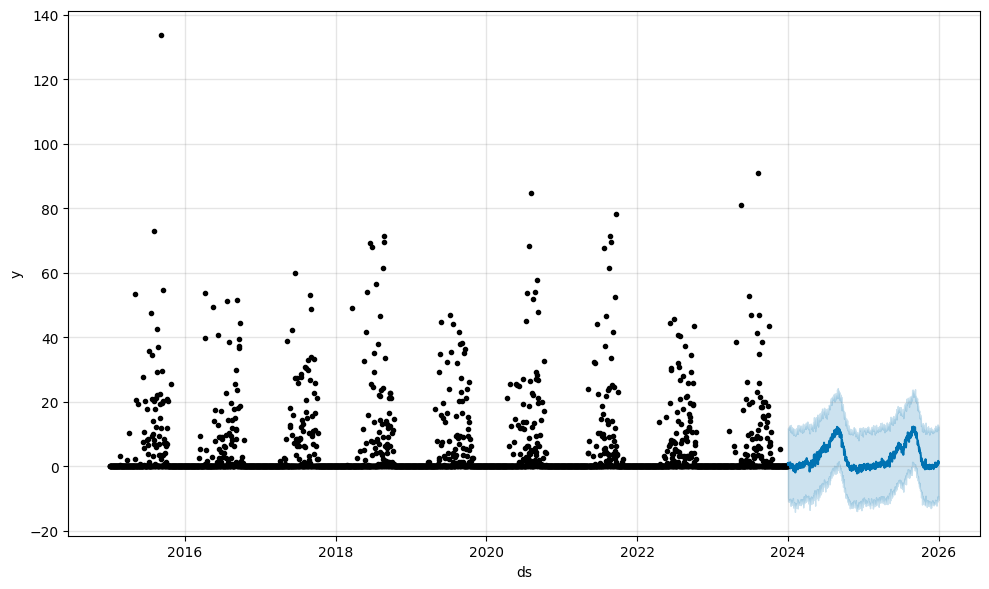

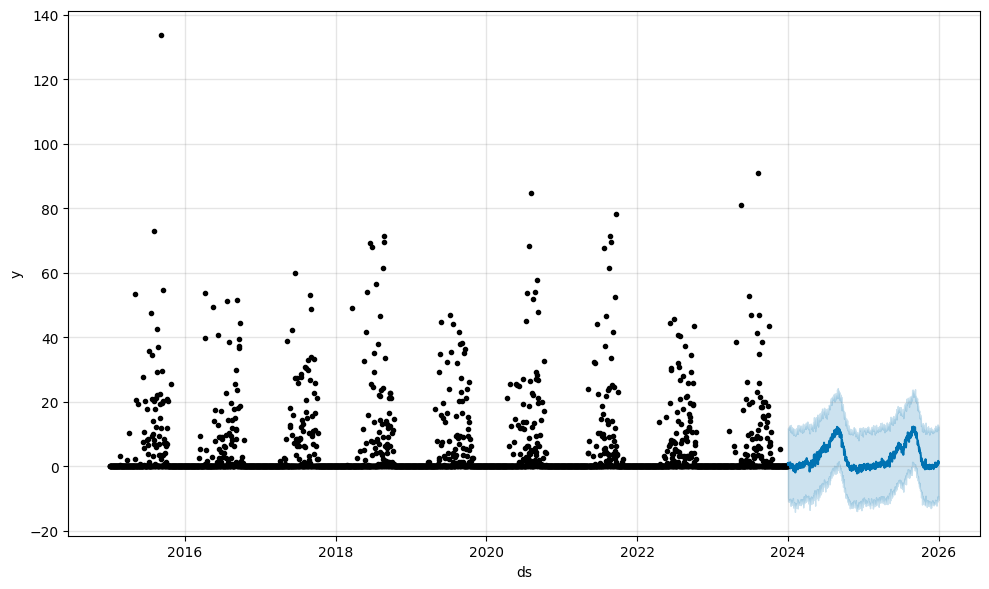

In [13]:
Calcul_Kandi["Resultats"].plot(Calcul_Kandi["Forecast"])

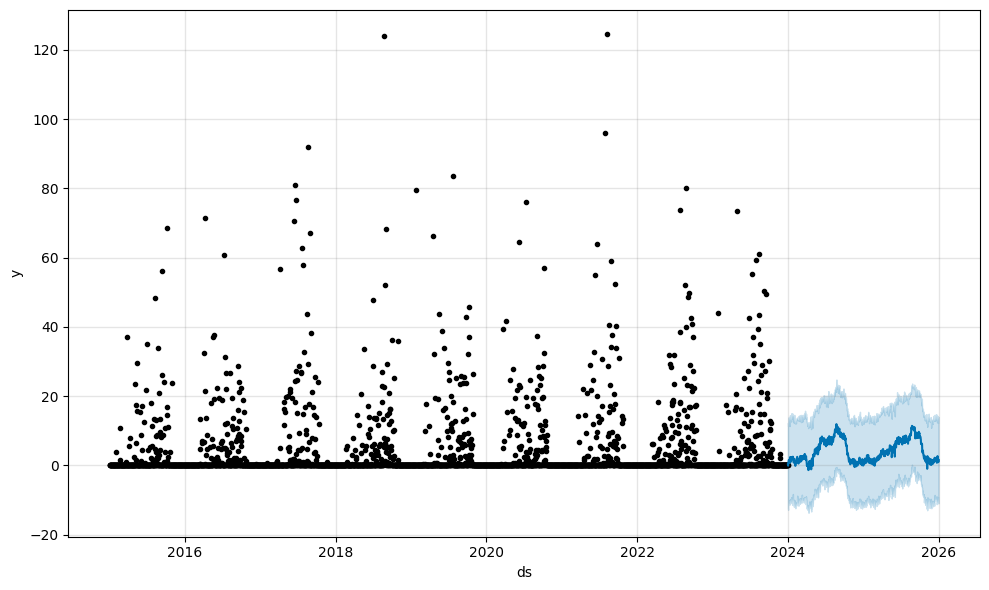

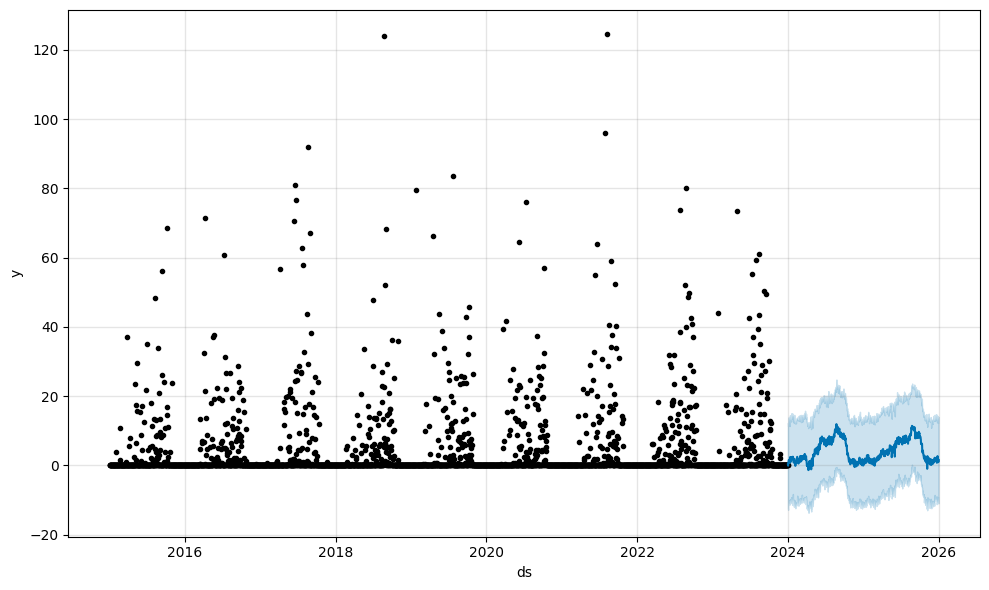

In [14]:
Calcul_Parakou["Resultats"].plot(Calcul_Parakou["Forecast"])

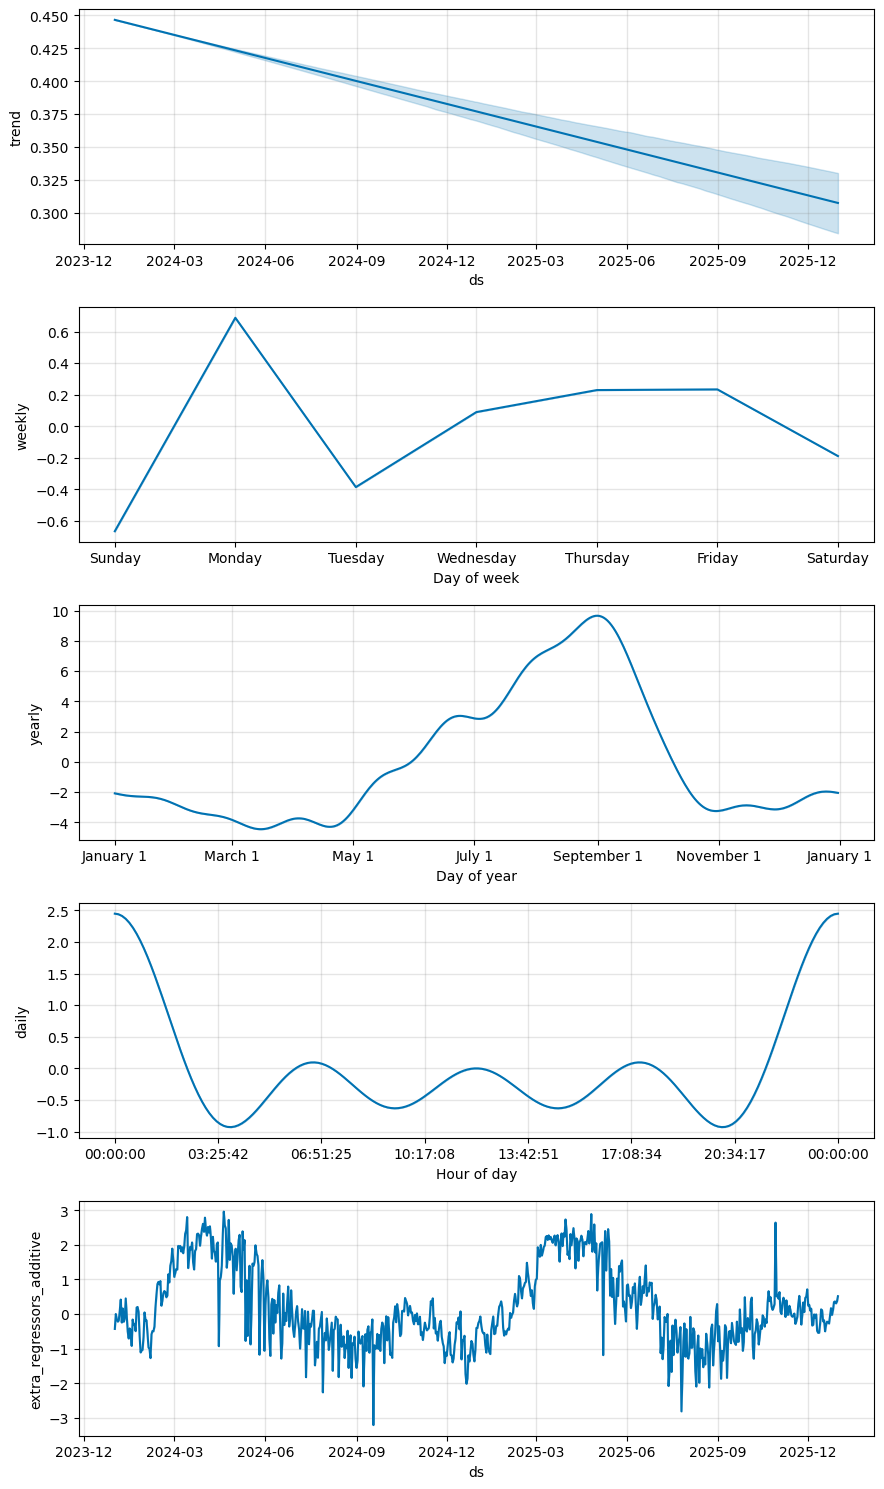

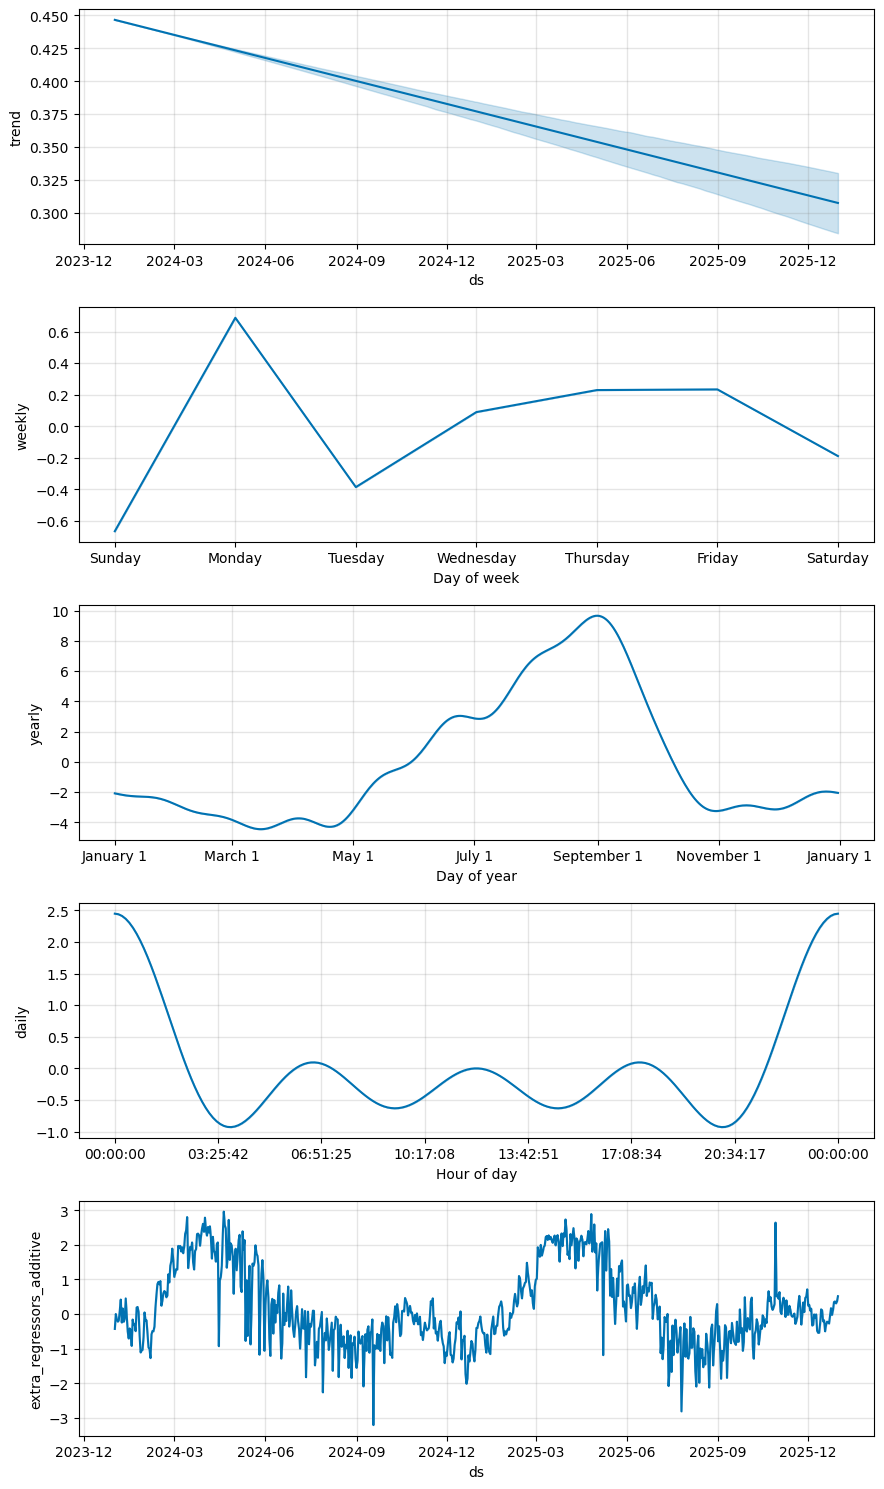

In [15]:
Calcul_Kandi["Resultats"].plot_components(Calcul_Kandi["Forecast"])

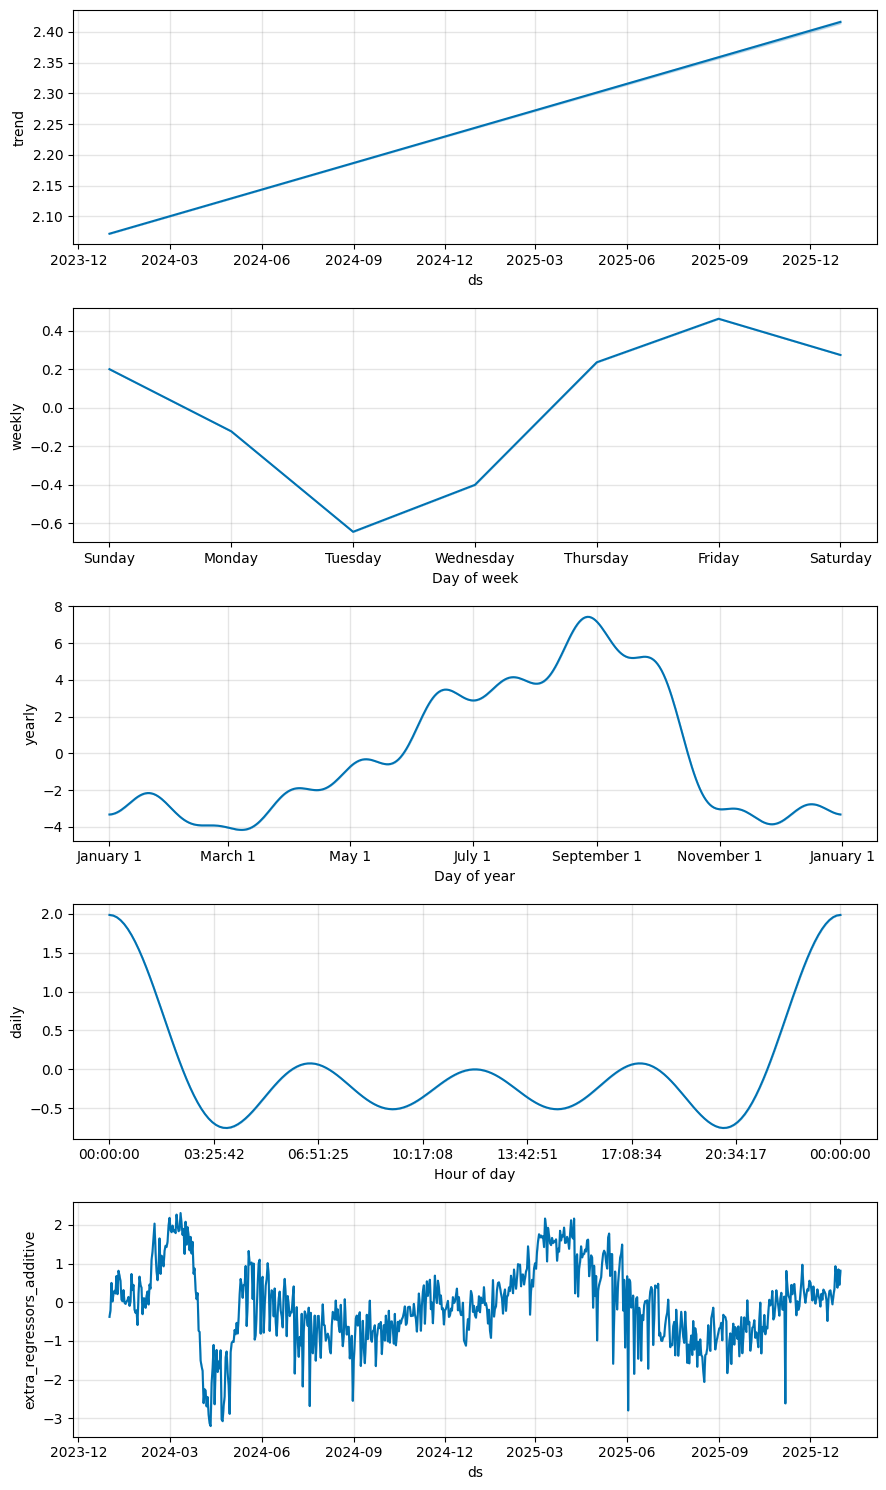

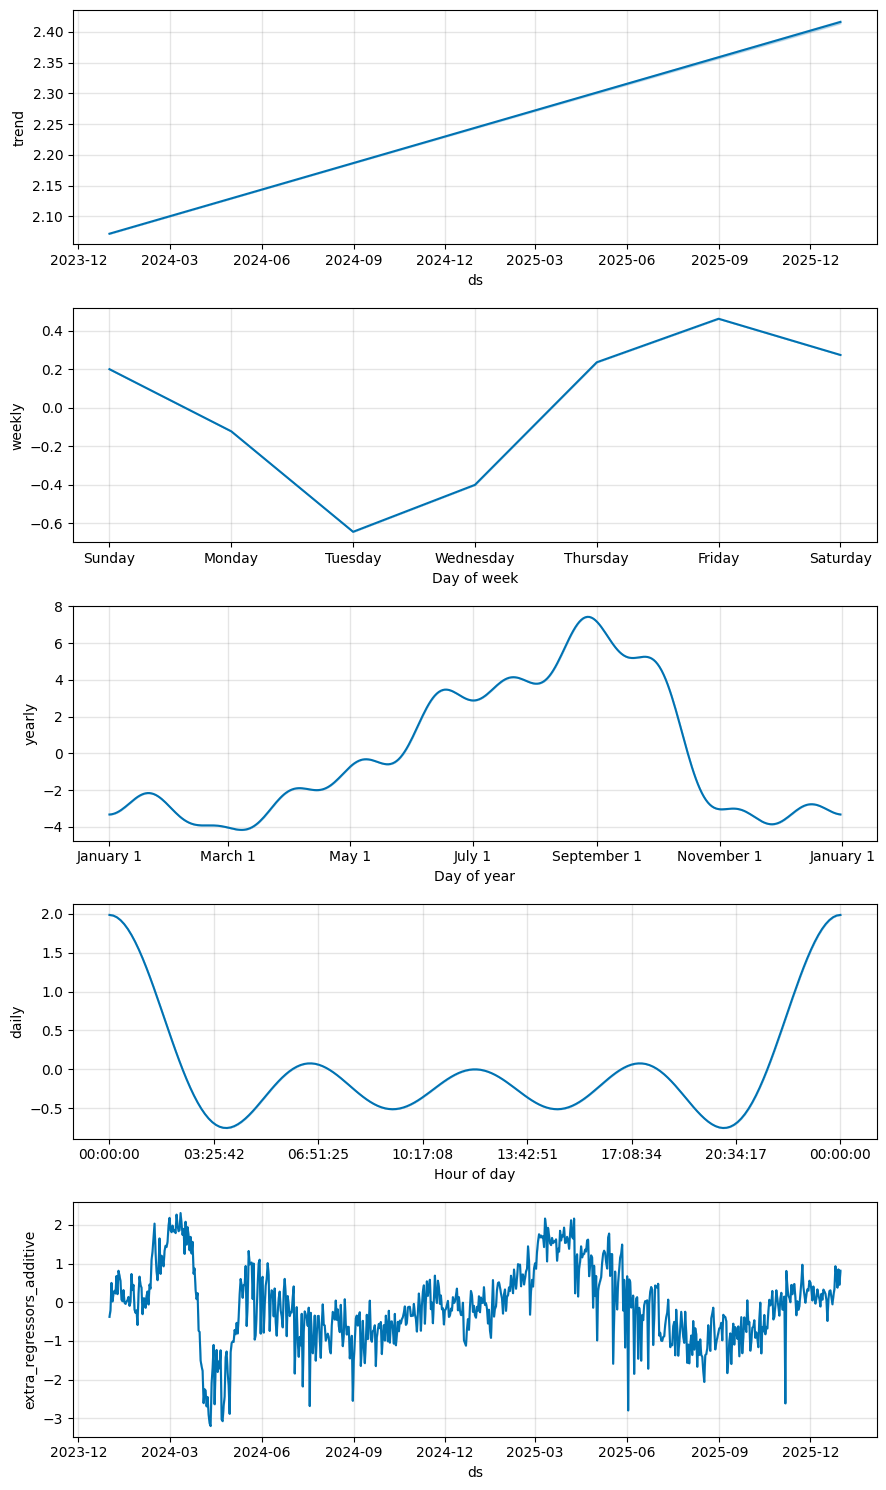

In [16]:
Calcul_Parakou["Resultats"].plot_components(Calcul_Parakou["Forecast"])

In [17]:
resultats=pd.concat([pd.DataFrame({"Station":["Kandi"],"MAE":Calcul_Kandi["MAE"],"RMSE":Calcul_Kandi["RMSE"]}),
                    pd.DataFrame({"Station":["Parakou"],"MAE":Calcul_Parakou["MAE"],"RMSE":Calcul_Parakou["RMSE"]})],axis=0)


resultats

,Station,MAE,RMSE
0,Kandi,4.310590,9.199159
0,Parakou,5.436776,10.935978


In [18]:
resultats.to_csv("data/resultats_prophet_avec_VE.csv",index=False)